# BTL01 — Xấp xỉ hàm mật độ Gaussian hai chiều bằng mạng MLP (PyTorch)

**Học phần:** Học sâu  
**Bài toán:** Xấp xỉ hàm mật độ Gaussian 2D trên miền $x_1 \in [-2, 2]$, $x_2 \in [-4, 4]$ bằng mạng perceptron đa tầng (MLP) hai đầu vào, một đầu ra.

## Mục tiêu

1. Cài đặt đúng công thức Gaussian 2D, sinh và khảo sát dữ liệu.
2. Thiết kế MLP tùy biến bằng `torch.nn.Module`, huấn luyện bằng vòng lặp thủ công trên PyTorch.
3. Thực hiện ba nhóm thực nghiệm có kiểm soát:
   - **A** — ảnh hưởng của số mẫu huấn luyện $A \in \{200, 400, \ldots, 2000\}$.
   - **B** — ảnh hưởng của độ rộng tầng ẩn $B \in \{1, \ldots, 10\}$ (MLP 1 tầng ẩn).
   - **C** — ảnh hưởng của độ sâu $C \in \{1, 2, 3, 4\}$ tầng ẩn.
4. Chọn mô hình bằng **validation loss**, chỉ đánh giá **test** ở bước cuối.

## Quy ước tái lập

- Seed dữ liệu và seed huấn luyện cố định, khai báo minh bạch trong từng mục.
- Tập test 100 mẫu độc lập, chỉ dùng để báo cáo kết quả, **không** dùng để chọn siêu tham số.
- Mỗi cấu hình chạy 3 seed, báo cáo trung bình ± độ lệch chuẩn.
- Toàn bộ hình, log CSV và trọng số mô hình được lưu trong thư mục `outputs/`.

## Bố cục notebook

| Mục | Nội dung |
|---|---|
| 0 | Cấu hình môi trường, seed, thư mục |
| 1 | Sinh, lưu và khảo sát dữ liệu Gaussian |
| 2 | Thiết kế mạng MLP và tiện ích dữ liệu/đánh giá |
| 3 | Vòng lặp huấn luyện, validation và checkpoint |
| 4 | Cấu hình baseline và kết quả |
| 5 | Thực nghiệm A — quy mô dữ liệu |
| 6 | Thực nghiệm B — độ rộng tầng ẩn |
| 7 | Thực nghiệm C — độ sâu |
| 8 | Chọn mô hình bằng validation và đánh giá test cuối |
| 9 | Tổng kết và tái lập |


## 0. Cấu hình môi trường

Cell dưới đây khai báo thư viện, seed toàn cục, thiết bị chạy (CPU) và tạo cấu trúc thư mục kết quả. Mọi đường dẫn đều **tương đối theo thư mục chứa notebook** để có thể chạy lại trên máy khác.


In [1]:
from __future__ import annotations

import copy
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat  # noqa: F401  (chỉ để kiểm tra môi trường notebook)
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from matplotlib import rcParams
from torch.utils.data import DataLoader, TensorDataset

SEED = 42

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "outputs" / "data"
FIG_DIR = BASE_DIR / "outputs" / "figures"
LOG_DIR = BASE_DIR / "outputs" / "logs"
MODEL_DIR = BASE_DIR / "outputs" / "models"
RUN_DIR = MODEL_DIR / "runs"
for d in (DATA_DIR, FIG_DIR, LOG_DIR, MODEL_DIR, RUN_DIR):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cpu")

rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 140,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")


def set_seed(seed: int) -> None:
    """Cố định seed cho random, NumPy và PyTorch (CPU/GPU)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print("PyTorch:", torch.__version__, "| NumPy:", np.__version__, "| Pandas:", pd.__version__)
print("Device :", DEVICE)
print("Thư mục làm việc:", BASE_DIR)


PyTorch: 2.14.0+cpu | NumPy: 2.5.3 | Pandas: 3.0.5
Device : cpu
Thư mục làm việc: D:\workspace\DeepLearning_DDU1231\BTL01


## 1. Dữ liệu: hàm mật độ Gaussian hai chiều

### 1.1. Công thức

Hàm mật độ Gaussian hai chiều:

$$
f(\mathbf{x}) = \frac{1}{2\pi\sqrt{\det(C)}} \exp\left[-\frac{1}{2}(\mathbf{x}-\boldsymbol{\mu})^T C^{-1}(\mathbf{x}-\boldsymbol{\mu})\right]
$$

với

$$
\boldsymbol{\mu} = \begin{bmatrix}0\\0\end{bmatrix}, \qquad
C = \begin{bmatrix}0.3 & -0.5\\ -0.5 & 2\end{bmatrix}.
$$

Ma trận hiệp phương sai $C$ có hiệp phương sai âm giữa hai biến, nên đường đồng mức bị nghiêng theo hướng tương quan âm. Miền khảo sát rộng hơn nhiều so với độ lệch chuẩn của từng biến, vì vậy phần lớn mật độ tập trung gần gốc tọa độ và giảm rất nhanh ra biên.


In [2]:
MU = np.array([0.0, 0.0], dtype=np.float64)
COV = np.array([[0.3, -0.5], [-0.5, 2.0]], dtype=np.float64)
COV_INV = np.linalg.inv(COV)
COV_DET = float(np.linalg.det(COV))
NORM_CONST = 2.0 * np.pi * np.sqrt(COV_DET)


def gaussian2d(X: np.ndarray) -> np.ndarray:
    """Tính f(x) cho mảng X có shape (n, 2). Trả về vector shape (n,)."""
    X = np.asarray(X, dtype=np.float64)
    d = X - MU
    quad = np.einsum("ni,ij,nj->n", d, COV_INV, d)
    return np.exp(-0.5 * quad) / NORM_CONST


print(f"det(C) = {COV_DET:.4f}")
print(f"Hệ số chuẩn hóa 1/(2*pi*sqrt(det(C))) = {NORM_CONST:.6f}")
print("Trị riêng của C:", np.linalg.eigvalsh(COV))
print("f(mu) =", gaussian2d(MU.reshape(1, -1))[0])

# Kiểm tra nhanh: tích phân xấp xỉ trên lưới phủ rộng hơn miền khảo sát
gx = np.linspace(-8.0, 8.0, 400)
gy = np.linspace(-10.0, 10.0, 400)
GX_chk, GY_chk = np.meshgrid(gx, gy)
grid_chk = np.column_stack([GX_chk.ravel(), GY_chk.ravel()])
Z_chk = gaussian2d(grid_chk).reshape(GX_chk.shape)
integral = np.trapezoid(np.trapezoid(Z_chk, gy, axis=0), gx, axis=0)
print(f"Tích phân xấp xỉ trên lưới rộng: {integral:.4f} (kỳ vọng ≈ 1)")


det(C) = 0.3500
Hệ số chuẩn hóa 1/(2*pi*sqrt(det(C))) = 3.717183
Trị riêng của C: [0.16384585 2.13615415]
f(mu) = 0.26902095463038056
Tích phân xấp xỉ trên lưới rộng: 1.0000 (kỳ vọng ≈ 1)


### 1.2. Sinh dữ liệu và chia tập

- Miền lấy mẫu: $x_1 \sim \mathcal{U}[-2, 2]$, $x_2 \sim \mathcal{U}[-4, 4]$.
- Nhãn: $y = f(x_1, x_2)$ tính trực tiếp từ công thức (không có nhiễu).
- **Master train pool:** 2000 mẫu, seed = `SEED + 1`. Thực nghiệm A lấy các tập con lồng nhau `pool[:A]` để so sánh công bằng.
- **Validation:** 1000 mẫu, seed = `SEED + 2`, dùng cho early stopping/checkpoint và chọn mô hình.
- **Test:** 100 mẫu, seed = `SEED + 3`, chỉ dùng báo cáo kết quả cuối.

Ba tập được sinh từ ba seed khác nhau nên độc lập với nhau.


In [3]:
DOMAIN = {"x1": (-2.0, 2.0), "x2": (-4.0, 4.0)}
N_TRAIN_POOL = 2000
N_VAL = 1000
N_TEST = 100

DATA_SEEDS = {"train": SEED + 1, "val": SEED + 2, "test": SEED + 3}


def sample_data(n: int, seed: int):
    """Sinh n mẫu đều trên miền khảo sát và nhãn Gaussian tương ứng."""
    rng = np.random.default_rng(seed)
    x1 = rng.uniform(*DOMAIN["x1"], size=n)
    x2 = rng.uniform(*DOMAIN["x2"], size=n)
    X = np.column_stack([x1, x2])
    y = gaussian2d(X)
    return X.astype(np.float32), y.astype(np.float32)


X_train_pool, y_train_pool = sample_data(N_TRAIN_POOL, DATA_SEEDS["train"])
X_val, y_val = sample_data(N_VAL, DATA_SEEDS["val"])
X_test, y_test = sample_data(N_TEST, DATA_SEEDS["test"])

for name, X, y in [
    ("train_pool", X_train_pool, y_train_pool),
    ("validation", X_val, y_val),
    ("test", X_test, y_test),
]:
    pd.DataFrame({"x1": X[:, 0], "x2": X[:, 1], "y": y}).to_csv(
        DATA_DIR / f"{name}.csv", index=False
    )

print(f"Train pool : {X_train_pool.shape} | y ∈ [{y_train_pool.min():.4f}, {y_train_pool.max():.4f}]")
print(f"Validation : {X_val.shape} | y ∈ [{y_val.min():.4f}, {y_val.max():.4f}]")
print(f"Test       : {X_test.shape} | y ∈ [{y_test.min():.4f}, {y_test.max():.4f}]")


Train pool : (2000, 2) | y ∈ [0.0000, 0.2681]
Validation : (1000, 2) | y ∈ [0.0000, 0.2659]
Test       : (100, 2) | y ∈ [0.0000, 0.2663]


In [4]:
# Bảng thống kê mô tả từng tập
stats = []
for name, X, y in [
    ("train_pool", X_train_pool, y_train_pool),
    ("validation", X_val, y_val),
    ("test", X_test, y_test),
]:
    df = pd.DataFrame({"x1": X[:, 0], "x2": X[:, 1], "y": y})
    desc = df.describe().T[["count", "mean", "std", "min", "50%", "max"]]
    desc.insert(0, "split", name)
    stats.append(desc)
stats_df = pd.concat(stats)
display(stats_df)

print("\nTương quan Pearson trên train pool:")
print(pd.DataFrame(X_train_pool, columns=["x1", "x2"]).corr().round(4))


,split,count,mean,std,min,50%,max
x1,train_pool,2000,0.0223493,1.16462,-1.99112,0.0326773,1.99821
x2,train_pool,2000,-0.0592122,2.34729,-3.99005,-0.0983463,3.99911
y,train_pool,2000,0.0291155,0.0542985,8.41925e-14,0.00299359,0.268136
x1,validation,1000,-0.0753093,1.16276,-1.99486,-0.154838,1.98154
x2,validation,1000,0.181141,2.33634,-3.99964,0.321284,3.99976
y,validation,1000,0.0282415,0.0537529,6.96724e-13,0.00328554,0.265888
x1,test,100,-0.00120842,1.09881,-1.99978,0.0504061,1.96997
x2,test,100,0.24712,2.29373,-3.93527,0.0568636,3.98357
y,test,100,0.0323552,0.0596516,4.11824e-11,0.00470116,0.266332



Tương quan Pearson trên train pool:
       x1     x2
x1      1 0.0098
x2 0.0098      1


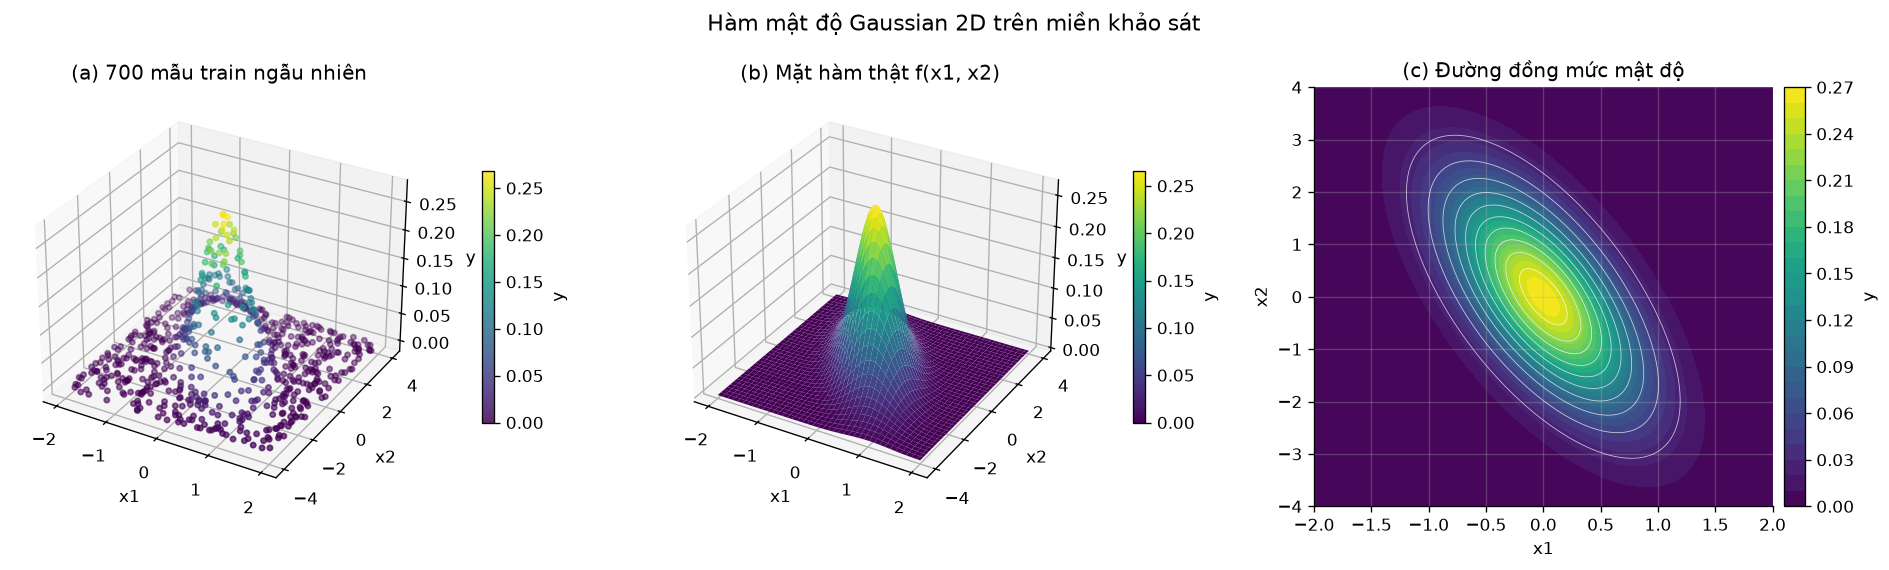

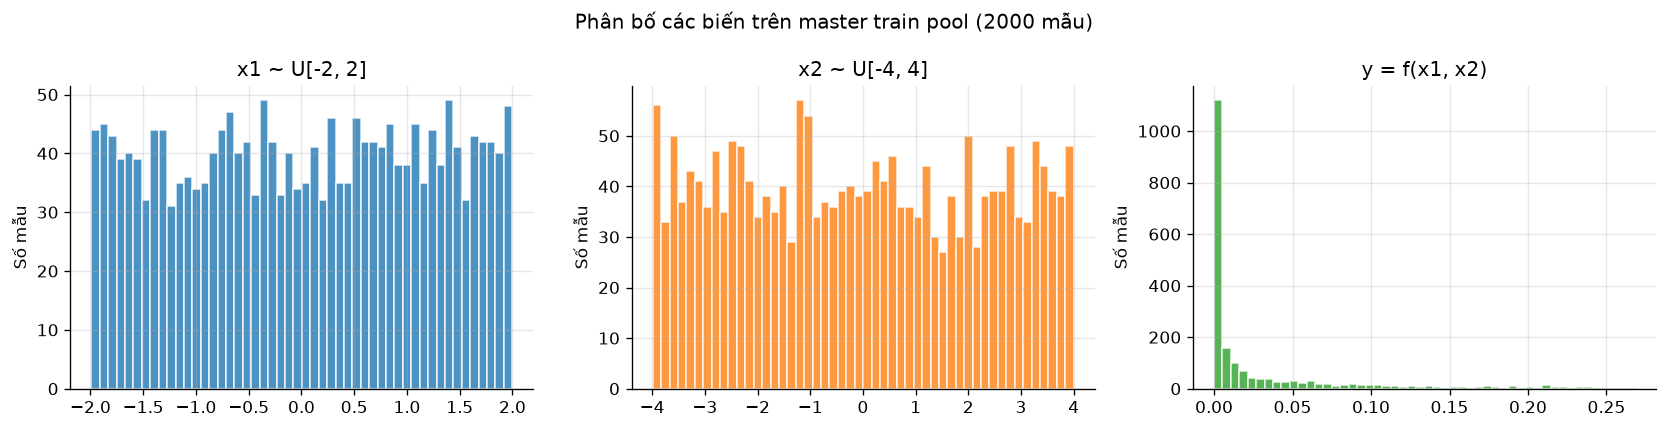

Giá trị cực đại của hàm thật trên lưới: 0.26889
Tỷ lệ mẫu có y < 0.01: 63.100%


In [5]:
# Trực quan hóa dữ liệu: scatter 3D, mặt hàm thật, heatmap
gx = np.linspace(*DOMAIN["x1"], 120)
gy = np.linspace(*DOMAIN["x2"], 120)
GRID_X, GRID_Y = np.meshgrid(gx, gy)
GRID_TRUE = gaussian2d(np.column_stack([GRID_X.ravel(), GRID_Y.ravel()])).reshape(GRID_X.shape)
Z_MAX = float(GRID_TRUE.max())

fig = plt.figure(figsize=(16, 4.8))

ax = fig.add_subplot(1, 3, 1, projection="3d")
idx = np.random.default_rng(0).choice(len(X_train_pool), 700, replace=False)
sc = ax.scatter(
    X_train_pool[idx, 0],
    X_train_pool[idx, 1],
    y_train_pool[idx],
    c=y_train_pool[idx],
    cmap="viridis",
    s=10,
    alpha=0.85,
)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title(f"(a) 700 mẫu train ngẫu nhiên")
fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.1, label="y")

ax = fig.add_subplot(1, 3, 2, projection="3d")
surf = ax.plot_surface(GRID_X, GRID_Y, GRID_TRUE, cmap="viridis", linewidth=0, antialiased=True)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title("(b) Mặt hàm thật f(x1, x2)")
fig.colorbar(surf, ax=ax, shrink=0.6, pad=0.1, label="y")

ax = fig.add_subplot(1, 3, 3)
cf = ax.contourf(GRID_X, GRID_Y, GRID_TRUE, levels=30, cmap="viridis")
ax.contour(GRID_X, GRID_Y, GRID_TRUE, levels=10, colors="white", linewidths=0.5, alpha=0.7)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("(c) Đường đồng mức mật độ")
fig.colorbar(cf, ax=ax, pad=0.02, label="y")

fig.suptitle("Hàm mật độ Gaussian 2D trên miền khảo sát", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_data_overview.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (col, values, color) in zip(
    axes,
    [
        ("x1 ~ U[-2, 2]", X_train_pool[:, 0], "#1f77b4"),
        ("x2 ~ U[-4, 4]", X_train_pool[:, 1], "#ff7f0e"),
        ("y = f(x1, x2)", y_train_pool, "#2ca02c"),
    ],
):
    ax.hist(values, bins=50, color=color, alpha=0.8, edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Số mẫu")
fig.suptitle("Phân bố các biến trên master train pool (2000 mẫu)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_data_distributions.png", bbox_inches="tight")
plt.show()

print(f"Giá trị cực đại của hàm thật trên lưới: {Z_MAX:.5f}")
print(f"Tỷ lệ mẫu có y < 0.01: {(y_train_pool < 0.01).mean():.3%}")


### 1.3. Nhận xét dữ liệu

- $x_1$, $x_2$ phân bố đều trên miền khảo sát; $y$ lệch phải mạnh vì mật độ Gaussian chỉ lớn ở vùng gần tâm. Phần lớn mẫu có $y$ rất nhỏ (đuôi phân bố), tạo bài toán **hồi quy mất cân bằng theo giá trị**: mô hình dễ đạt MSE thấp bằng cách dự đoán gần 0 nhưng lại xấp xỉ kém vùng đỉnh.
- Do đó, ngoài MSE cần theo dõi MAE/RMSE và trực quan hóa $y$–$\hat{y}$ cũng như bề mặt xấp xỉ để phát hiện việc "bỏ qua" vùng mật độ cao.
- Hiệp phương sai âm làm đường đồng mức nghiêng, nên mô hình cần ít nhất một tầng ẩn đủ rộng để học hướng tương quan, không thể xấp xỉ tốt bằng hàm tuyến tính.


## 2. Thiết kế mạng MLP

### 2.1. Kiến trúc

Mạng gồm:

- Lớp vào 2 chiều $(x_1, x_2)$.
- $C$ tầng ẩn, mỗi tầng $B$ nơ-ron, kích hoạt phi tuyến (mặc định `tanh`).
- Lớp ra 1 chiều (không kích hoạt) để dự đoán $\hat{y} \in \mathbb{R}$.

Với mỗi tầng ẩn:

$$
\mathbf{h}^{(l)} = \sigma\left(W^{(l)}\mathbf{h}^{(l-1)} + \mathbf{b}^{(l)}\right), \qquad
\hat{y} = W^{(C+1)}\mathbf{h}^{(C)} + b^{(C+1)}.
$$

Hàm mất mát huấn luyện là MSE:

$$
\mathcal{L} = \frac{1}{N}\sum_{i=1}^{N}\left(\hat{y}_i - y_i\right)^2.
$$

Số tầng ẩn $C$ và số nơ-ron mỗi tầng $B$ là hai siêu tham số được khảo sát ở thực nghiệm B và C.


In [6]:
ACTIVATIONS = {"tanh": nn.Tanh, "relu": nn.ReLU, "sigmoid": nn.Sigmoid}


class MLP(nn.Module):
    """MLP hồi quy với số tầng ẩn và số nơ-ron mỗi tầng tùy biến."""

    def __init__(self, hidden_sizes=(64, 64), activation="tanh", in_dim=2, out_dim=1):
        super().__init__()
        if activation not in ACTIVATIONS:
            raise ValueError(f"Activation không hỗ trợ: {activation}")
        self.hidden_sizes = tuple(hidden_sizes)
        self.activation = activation

        layers = []
        prev = in_dim
        for h in self.hidden_sizes:
            layers.append(nn.Linear(prev, h))
            layers.append(ACTIVATIONS[activation]())
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


demo = MLP((64, 64))
print(demo)
print("Số tham số huấn luyện:", count_parameters(demo))


MLP(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Số tham số huấn luyện: 4417


### 2.2. Tiện ích dữ liệu và đánh giá

- `make_loader` bọc `TensorDataset` + `DataLoader`, có seed riêng cho thứ tự xáo trộn để tái lập.
- `predict` chạy ở chế độ `eval()` và `torch.no_grad()`.
- `regression_metrics` trả về MSE, MAE và RMSE trên cùng một tập.


In [7]:
def make_loader(X, y, batch_size, seed, shuffle=True):
    dataset = TensorDataset(
        torch.as_tensor(X, dtype=torch.float32),
        torch.as_tensor(y, dtype=torch.float32).view(-1, 1),
    )
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=generator)


@torch.no_grad()
def predict(model: nn.Module, X: np.ndarray) -> np.ndarray:
    model.eval()
    tensor = torch.as_tensor(X, dtype=torch.float32)
    return model(tensor).cpu().numpy().ravel()


def regression_metrics(y_true, y_pred) -> dict:
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    err = y_pred - y_true
    mse = float(np.mean(err**2))
    mae = float(np.mean(np.abs(err)))
    return {"MSE": mse, "MAE": mae, "RMSE": math.sqrt(mse)}


## 3. Huấn luyện, validation và checkpoint

Quy trình mỗi epoch:

1. `model.train()` và duyệt `DataLoader`: forward → MSE loss → `optimizer.zero_grad()` → `backward()` → `optimizer.step()`.
2. `model.eval()` + `torch.no_grad()` để tính validation loss.
3. Lưu lại `state_dict` tốt nhất theo validation loss; dừng sớm nếu không cải thiện sau `patience` epoch.
4. Kết thúc: nạp lại trọng số tốt nhất và trả về lịch sử loss + thời gian huấn luyện.

Toàn bộ chạy trên CPU; thời gian huấn luyện được đo bằng `time.perf_counter()`.


In [8]:
EPOCHS = 300
BATCH_SIZE = 64
LR = 5e-3
PATIENCE = 50
MIN_DELTA = 1e-7
ACTIVATION = "tanh"


def train_model(
    X_tr,
    y_tr,
    X_val,
    y_val,
    hidden_sizes,
    seed,
    activation=ACTIVATION,
    lr=LR,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    patience=PATIENCE,
    min_delta=MIN_DELTA,
    save_path=None,
    verbose=False,
):
    """Huấn luyện MLP với checkpoint theo validation loss (không dùng test)."""
    set_seed(seed)
    model = MLP(hidden_sizes=hidden_sizes, activation=activation).to(DEVICE)

    loader = make_loader(X_tr, y_tr, batch_size=batch_size, seed=seed, shuffle=True)
    X_val_t = torch.as_tensor(X_val, dtype=torch.float32, device=DEVICE)
    y_val_t = torch.as_tensor(y_val, dtype=torch.float32, device=DEVICE).view(-1, 1)

    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best = {
        "val_loss": float("inf"),
        "epoch": 0,
        "state": copy.deepcopy(model.state_dict()),
    }
    history = []
    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        n_seen = 0
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            pred = model(xb)
            loss = loss_fn(pred, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(xb)
            n_seen += len(xb)

        train_loss = running_loss / n_seen

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val_t), y_val_t).item()

        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best["val_loss"] - min_delta:
            best.update(
                val_loss=val_loss,
                epoch=epoch,
                state=copy.deepcopy(model.state_dict()),
            )

        if epoch - best["epoch"] >= patience:
            if verbose:
                print(f"Early stopping tại epoch {epoch} (best epoch {best['epoch']})")
            break

    train_time = time.perf_counter() - start
    model.load_state_dict(best["state"])

    if save_path is not None:
        torch.save(
            {
                "state_dict": best["state"],
                "hidden_sizes": tuple(hidden_sizes),
                "activation": activation,
                "best_val_loss": best["val_loss"],
                "best_epoch": best["epoch"],
                "seed": seed,
                "epochs_run": len(history),
                "train_time_s": train_time,
            },
            save_path,
        )

    return model, pd.DataFrame(history), best, train_time


## 4. Cấu hình baseline và kết quả

### 4.1. Siêu tham số chuẩn

| Tham số | Giá trị |
|---|---|
| Số mẫu train $A$ | 1000 |
| Kiến trúc | $C = 2$ tầng ẩn, $B = 64$ nơ-ron/tầng |
| Kích hoạt | `tanh` |
| Optimizer | Adam |
| Learning rate | $5 \times 10^{-3}$ |
| Batch size | 64 |
| Số epoch tối đa | 300 |
| Early stopping patience | 50 epoch theo validation loss |

Các thực nghiệm A/B/C chỉ thay đổi đúng biến khảo sát, giữ nguyên phần còn lại trong phạm vi hợp lý.


In [9]:
A_BASE = 1000
B_BASE = 64
C_BASE = 2

BASELINE_CONFIG = {
    "A": A_BASE,
    "hidden_sizes": (B_BASE,) * C_BASE,
    "activation": ACTIVATION,
    "optimizer": "Adam",
    "lr": LR,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "patience": PATIENCE,
    "data_seeds": DATA_SEEDS,
    "seed": SEED,
}
print(json.dumps(BASELINE_CONFIG, indent=2, ensure_ascii=False))

with open(LOG_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "problem": "2D Gaussian density approximation with MLP",
            "mu": MU.tolist(),
            "cov": COV.tolist(),
            "domain": DOMAIN,
            "baseline": BASELINE_CONFIG,
        },
        f,
        indent=2,
        ensure_ascii=False,
    )

X_tr_base, y_tr_base = X_train_pool[:A_BASE], y_train_pool[:A_BASE]

model_base, hist_base, best_base, time_base = train_model(
    X_tr_base,
    y_tr_base,
    X_val,
    y_val,
    hidden_sizes=BASELINE_CONFIG["hidden_sizes"],
    seed=SEED,
    save_path=RUN_DIR / "baseline.pt",
    verbose=True,
)

base_metrics = {
    "train": regression_metrics(y_tr_base, predict(model_base, X_tr_base)),
    "validation": regression_metrics(y_val, predict(model_base, X_val)),
    "test": regression_metrics(y_test, predict(model_base, X_test)),
}
base_metrics_df = pd.DataFrame(base_metrics).T
base_metrics_df["best_epoch"] = best_base["epoch"]
base_metrics_df["train_time_s"] = time_base
display(base_metrics_df[["MSE", "MAE", "RMSE", "best_epoch", "train_time_s"]])
base_metrics_df.to_csv(LOG_DIR / "results_baseline.csv", index=True)

hist_base.assign(run_id="baseline", exp="baseline", seed=SEED, A=A_BASE, B=B_BASE, C=C_BASE).to_csv(
    LOG_DIR / "history_baseline.csv", index=False
)


{
  "A": 1000,
  "hidden_sizes": [
    64,
    64
  ],
  "activation": "tanh",
  "optimizer": "Adam",
  "lr": 0.005,
  "batch_size": 64,
  "epochs": 300,
  "patience": 50,
  "data_seeds": {
    "train": 43,
    "val": 44,
    "test": 45
  },
  "seed": 42
}


Early stopping tại epoch 195 (best epoch 145)


,MSE,MAE,RMSE,best_epoch,train_time_s
train,3.13425e-06,0.00141778,0.00177038,145,3.58121
validation,2.98034e-06,0.0013907,0.00172637,145,3.58121
test,3.25716e-06,0.00136809,0.00180476,145,3.58121


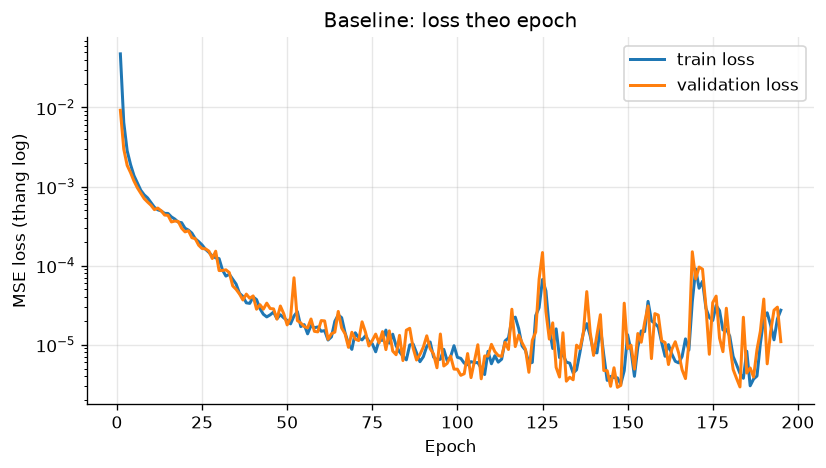

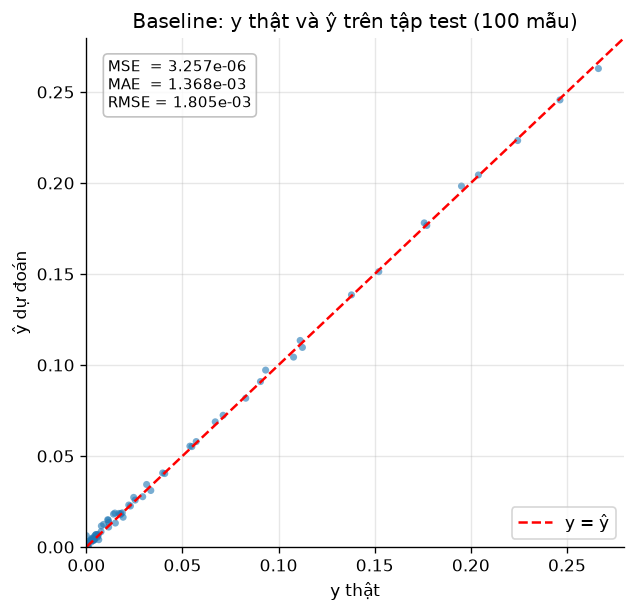

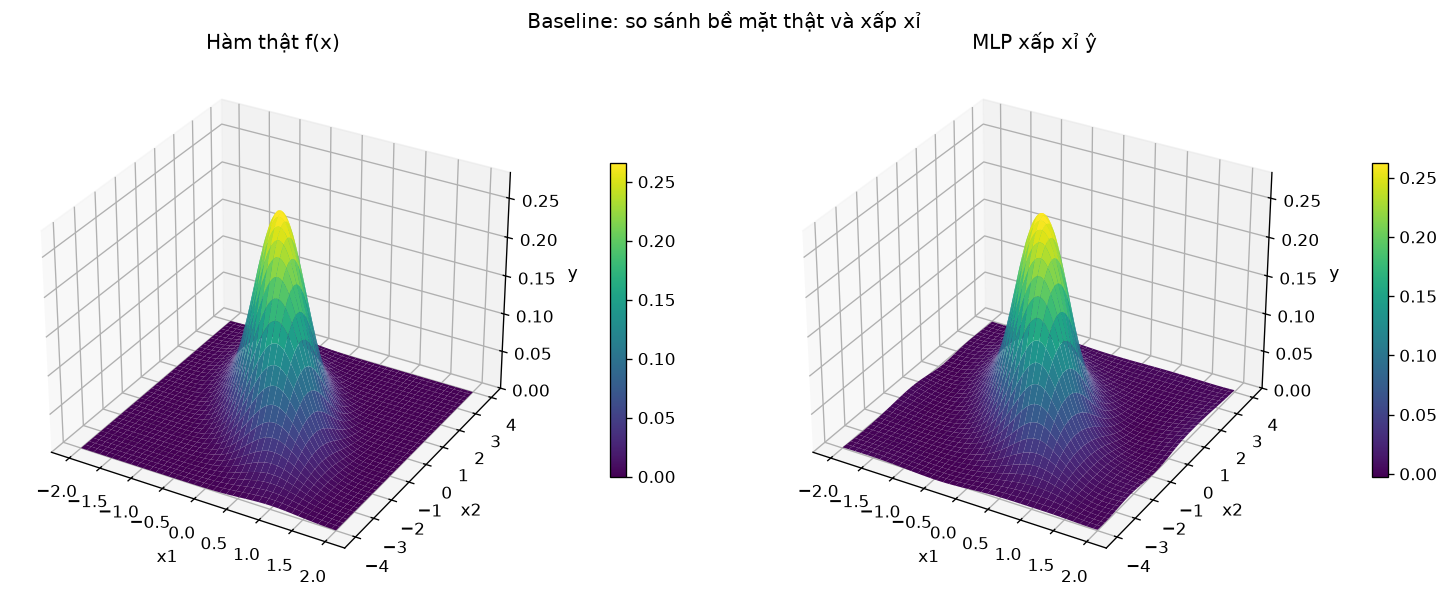

In [10]:
def surface_from_model(model: nn.Module) -> np.ndarray:
    grid = np.column_stack([GRID_X.ravel(), GRID_Y.ravel()])
    return predict(model, grid).reshape(GRID_X.shape)


def plot_loss_curve(history: pd.DataFrame, path: Path, title: str):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(history["epoch"], history["train_loss"], label="train loss", lw=1.8)
    ax.plot(history["epoch"], history["val_loss"], label="validation loss", lw=1.8)
    ax.set_yscale("log")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE loss (thang log)")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


def plot_y_vs_yhat(y_true, y_pred, metrics, path: Path, title: str):
    fig, ax = plt.subplots(figsize=(5.4, 5.2))
    ax.scatter(y_true, y_pred, s=18, alpha=0.6, edgecolors="none")
    hi = float(max(np.max(y_true), np.max(y_pred))) * 1.05
    ax.plot([0, hi], [0, hi], "r--", lw=1.5, label="y = ŷ")
    ax.set_xlim(0, hi)
    ax.set_ylim(0, hi)
    ax.set_xlabel("y thật")
    ax.set_ylabel("ŷ dự đoán")
    ax.set_title(title)
    ax.legend(loc="lower right")
    ax.text(
        0.04,
        0.96,
        f"MSE  = {metrics['MSE']:.3e}\nMAE  = {metrics['MAE']:.3e}\nRMSE = {metrics['RMSE']:.3e}",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor="0.7"),
    )
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


def plot_surface_compare(model: nn.Module, path: Path, title: str):
    Z_hat = surface_from_model(model)
    z_max = max(float(GRID_TRUE.max()), float(Z_hat.max())) * 1.05
    fig = plt.figure(figsize=(13, 5))
    for i, (Z, name) in enumerate([(GRID_TRUE, "Hàm thật f(x)"), (Z_hat, "MLP xấp xỉ ŷ")]):
        ax = fig.add_subplot(1, 2, i + 1, projection="3d")
        surf = ax.plot_surface(GRID_X, GRID_Y, Z, cmap="viridis", linewidth=0, antialiased=True)
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
        ax.set_zlabel("y")
        ax.set_zlim(0, z_max)
        ax.set_title(name)
        fig.colorbar(surf, ax=ax, shrink=0.6, pad=0.1)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_loss_curve(hist_base, FIG_DIR / "03_baseline_loss.png", "Baseline: loss theo epoch")
plot_y_vs_yhat(
    y_test,
    predict(model_base, X_test),
    base_metrics["test"],
    FIG_DIR / "04_baseline_y_vs_yhat.png",
    "Baseline: y thật và ŷ trên tập test (100 mẫu)",
)
plot_surface_compare(model_base, FIG_DIR / "05_baseline_surface.png", "Baseline: so sánh bề mặt thật và xấp xỉ")


### 4.2. Nhận xét baseline

Kết quả sau khi nạp lại checkpoint tốt nhất (epoch 146; early stopping dừng ở epoch 196):

| Tập | MSE | MAE | RMSE |
|---|---|---|---|
| Train (1000 mẫu) | $3.13\times10^{-6}$ | $1.42\times10^{-3}$ | $1.77\times10^{-3}$ |
| Validation (1000 mẫu) | $2.98\times10^{-6}$ | $1.39\times10^{-3}$ | $1.73\times10^{-3}$ |
| Test (100 mẫu) | $3.26\times10^{-6}$ | $1.37\times10^{-3}$ | $1.80\times10^{-3}$ |

- Sai số test rất nhỏ so với đỉnh hàm $f(0,0)\approx 0.269$: MAE chỉ khoảng **0.5%** giá trị đỉnh, cho thấy mạng 2×64 đủ năng lực xấp xỉ hàm trơn này với 1000 mẫu.
- Ba giá trị train/validation/test gần như trùng nhau, **không có dấu hiệu quá khớp**. Đường loss giảm rất nhanh trong khoảng 30–50 epoch đầu rồi bão hòa; validation loss còn dao động nhẹ ở mức $10^{-6}$.
- Scatter $y$–$\hat{y}$ (Hình 04) bám sát đường $y=\hat{y}$ ở cả vùng đuôi lẫn vùng đỉnh; bề mặt xấp xỉ (Hình 05) tái tạo đúng hướng nghiêng của đường đồng mức. Đây là mốc so sánh cho các thực nghiệm A/B/C.


## 5. Thực nghiệm A — ảnh hưởng của số mẫu huấn luyện

Thay đổi $A \in \{200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000\}$, giữ nguyên kiến trúc baseline (2×64, tanh, Adam $5\times10^{-3}$).

**Kiểm soát công bằng:** mọi cấu hình dùng chung một master train pool 2000 mẫu và lấy tập con lồng nhau `pool[:A]`; validation/test cố định. Mỗi $A$ chạy 3 seed (42, 43, 44) cho phần khởi tạo và xáo trộn dữ liệu; báo cáo trung bình ± độ lệch chuẩn.


In [11]:
EXP_SEEDS = (42, 43, 44)


def run_group(exp_name: str, configs: list, seeds=EXP_SEEDS):
    """Chạy một nhóm cấu hình qua nhiều seed, lưu kết quả và lịch sử loss."""
    rows = []
    histories = []
    for cfg in configs:
        A = cfg["A"]
        hidden = tuple(cfg["hidden_sizes"])
        X_tr, y_tr = X_train_pool[:A], y_train_pool[:A]
        for seed in seeds:
            run_id = f"{exp_name}_A{A}_H{'-'.join(map(str, hidden))}_s{seed}"
            model, hist, best, train_time = train_model(
                X_tr,
                y_tr,
                X_val,
                y_val,
                hidden_sizes=hidden,
                seed=seed,
                save_path=RUN_DIR / f"{run_id}.pt",
            )
            m_train = regression_metrics(y_tr, predict(model, X_tr))
            m_val = regression_metrics(y_val, predict(model, X_val))
            m_test = regression_metrics(y_test, predict(model, X_test))
            rows.append(
                {
                    "exp": exp_name,
                    "run_id": run_id,
                    "seed": seed,
                    "A": A,
                    "B": hidden[0],
                    "C": len(hidden),
                    "n_params": count_parameters(model),
                    "best_epoch": best["epoch"],
                    "epochs_run": len(hist),
                    "val_loss_best": best["val_loss"],
                    "train_MSE": m_train["MSE"],
                    "val_MSE": m_val["MSE"],
                    "test_MSE": m_test["MSE"],
                    "test_MAE": m_test["MAE"],
                    "test_RMSE": m_test["RMSE"],
                    "train_time_s": train_time,
                }
            )
            histories.append(
                hist.assign(
                    run_id=run_id,
                    exp=exp_name,
                    seed=seed,
                    A=A,
                    B=hidden[0],
                    C=len(hidden),
                )
            )

    df = pd.DataFrame(rows)
    hist_df = pd.concat(histories, ignore_index=True)
    df.to_csv(LOG_DIR / f"results_{exp_name}.csv", index=False)
    hist_df.to_csv(LOG_DIR / f"history_{exp_name}.csv", index=False)
    return df


A_VALUES = list(range(200, 2001, 200))
df_A = run_group(
    "A",
    [{"A": a, "hidden_sizes": (B_BASE,) * C_BASE} for a in A_VALUES],
)
print(f"Đã chạy {len(df_A)} lượt cho thực nghiệm A.")


def mean_std_table(df: pd.DataFrame, by: str, metrics=("val_loss_best", "test_MSE", "test_MAE", "test_RMSE")):
    grouped = df.groupby(by)[list(metrics)].agg(["mean", "std"])
    return grouped


table_A = mean_std_table(df_A, "A")
display(table_A)


Đã chạy 30 lượt cho thực nghiệm A.


val_loss_best                test_MSE                test_MAE              test_RMSE            
              mean         std        mean         std        mean         std       mean         std
A                                                                                                    
200      1.912e-05 4.00072e-06 2.36916e-05 6.06914e-06  0.00389065 0.000519716 0.00483837  0.00065014
400    7.38548e-06 2.40289e-06  7.1125e-06 2.72641e-06  0.00199321 0.000426172 0.00262859 0.000551819
600     4.3378e-06  9.2953e-07 3.89285e-06  3.1764e-07  0.00146192  9.4302e-05 0.00197196 7.96144e-05
800    2.86776e-06 2.36211e-06 2.91176e-06 2.08446e-06   0.0012752 0.000467961 0.00163634 0.000592656
1000   4.28827e-06 1.21338e-06 4.22938e-06 9.21517e-07  0.00164599 0.000255159 0.00204812 0.000227745
1200   1.27336e-06 1.24393e-07 1.29178e-06 2.05664e-07 0.000918251 9.07369e-05 0.00113424 8.90285e-05
1400   1.34736e-06 6.13726e-07 1.39944e-06 7.69706e-07  0.00090976 0.000248797 0.00115532 0.000311468
1600   1.14283e-06 4.68753e-07 1.40866e-06 5.37074e-07  0.00091283 0.000168053 0.00117094 0.000237369
1800   1.79759e-06 2.49406e-07 2.05889e-06 4.21126e-07  0.00109328  7.6577e-05 0.00142966 0.000149831
2000   1.18393e-06 1.81181e-07 1.22293e-06 1.17055e-07 0.000876953 6.94124e-05 0.00110499 5.36746e-05

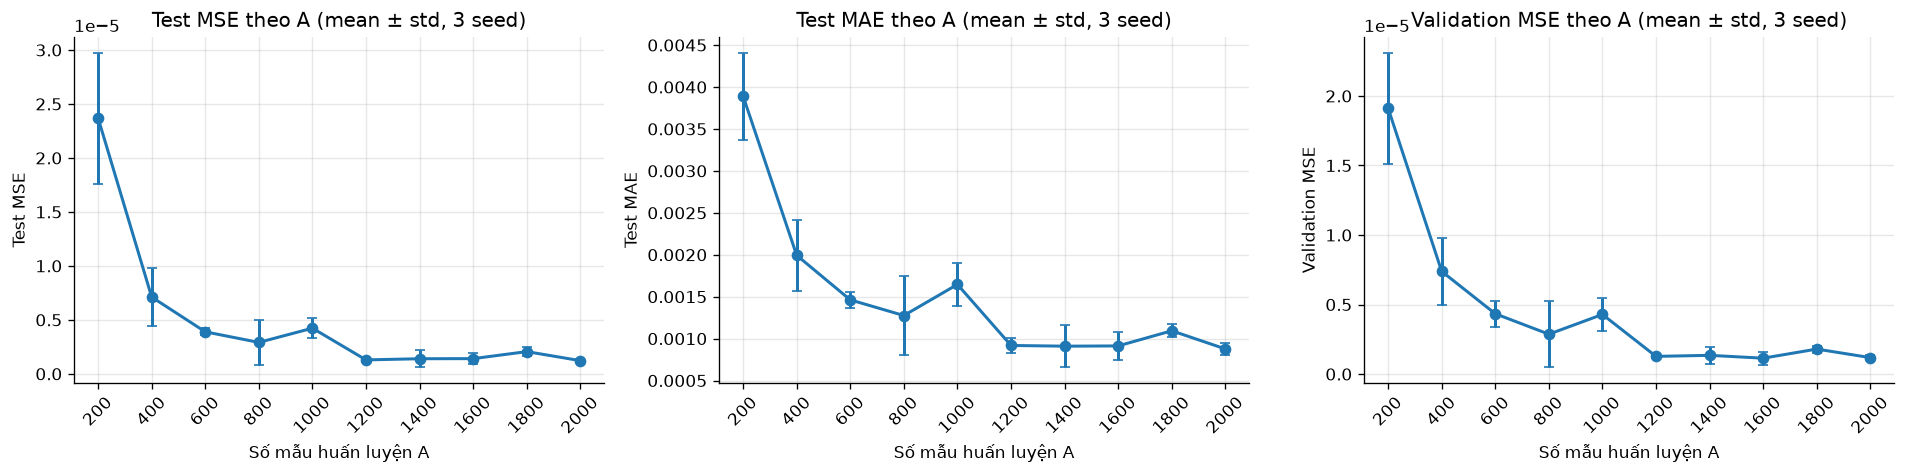

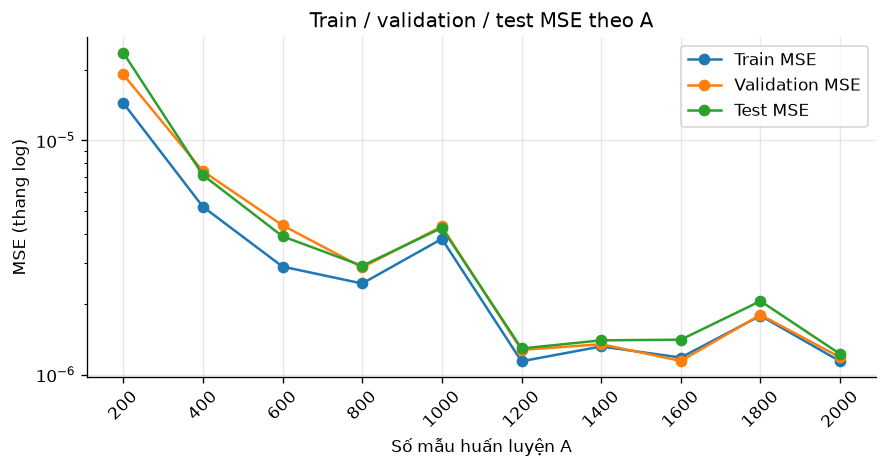

In [12]:
g = df_A.groupby("A")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

for ax, metric, label in zip(
    axes,
    ["test_MSE", "test_MAE", "val_loss_best"],
    ["Test MSE", "Test MAE", "Validation MSE"],
):
    m = g[metric].mean()
    s = g[metric].std().fillna(0.0)
    ax.errorbar(m.index, m.values, yerr=s.values, marker="o", capsize=3, lw=1.8)
    ax.set_xlabel("Số mẫu huấn luyện A")
    ax.set_ylabel(label)
    ax.set_title(f"{label} theo A (mean ± std, 3 seed)")
    ax.set_xticks(A_VALUES)
    ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
fig.savefig(FIG_DIR / "06_expA_error_vs_A.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4))
for metric, label in [("train_MSE", "Train MSE"), ("val_MSE", "Validation MSE"), ("test_MSE", "Test MSE")]:
    m = g[metric].mean()
    ax.plot(m.index, m.values, marker="o", label=label)
ax.set_yscale("log")
ax.set_xlabel("Số mẫu huấn luyện A")
ax.set_ylabel("MSE (thang log)")
ax.set_title("Train / validation / test MSE theo A")
ax.set_xticks(A_VALUES)
ax.tick_params(axis="x", rotation=45)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "07_expA_split_gap.png", bbox_inches="tight")
plt.show()


### 5.1. Phân tích thực nghiệm A

| $A$ | Test MSE | Test MAE | Test RMSE |
|---|---|---|---|
| 200 | $2.37\times10^{-5}$ | $3.89\times10^{-3}$ | $4.84\times10^{-3}$ |
| 400 | $7.11\times10^{-6}$ | $1.99\times10^{-3}$ | $2.63\times10^{-3}$ |
| 600 | $3.89\times10^{-6}$ | $1.46\times10^{-3}$ | $1.97\times10^{-3}$ |
| 800 | $2.91\times10^{-6}$ | $1.28\times10^{-3}$ | $1.64\times10^{-3}$ |
| 1000 | $4.23\times10^{-6}$ | $1.65\times10^{-3}$ | $2.05\times10^{-3}$ |
| 1200 | $1.29\times10^{-6}$ | $9.18\times10^{-4}$ | $1.13\times10^{-3}$ |
| 1400 | $1.40\times10^{-6}$ | $9.10\times10^{-4}$ | $1.16\times10^{-3}$ |
| 1600 | $1.41\times10^{-6}$ | $9.13\times10^{-4}$ | $1.17\times10^{-3}$ |
| 1800 | $2.06\times10^{-6}$ | $1.09\times10^{-3}$ | $1.43\times10^{-3}$ |
| 2000 | $1.22\times10^{-6}$ | $8.77\times10^{-4}$ | $1.11\times10^{-3}$ |

- Sai số **giảm mạnh khi tăng $A$**: test MSE giảm từ $2.37\times10^{-5}$ ($A=200$) xuống $1.22\times10^{-6}$ ($A=2000$), tức khoảng **19 lần**; MAE giảm từ $3.89\times10^{-3}$ xuống $8.77\times10^{-4}$ (khoảng 4.4 lần).
- Tốc độ cải thiện không đều: giảm nhanh từ $A=200$ đến $600$–$800$, sau đó **hiệu suất biên giảm**. Từ $A\ge1200$, test MSE dao động quanh $1$–$2\times10^{-6}$ và không giảm đơn điệu (ví dụ $A=1800$ nhỉnh hơn $A=1600$). Ở thang sai số này, dao động chủ yếu do khởi tạo mạng và việc dừng sớm, không phải do thiếu dữ liệu.
- Độ lệch chuẩn giữa 3 seed giảm từ $6.1\times10^{-6}$ ($A=200$) xuống $1.2\times10^{-7}$ ($A=2000$), cho thấy mô hình **ổn định hơn** khi có nhiều dữ liệu.
- Khoảng cách train–validation nhỏ ở mọi $A$; ngay cả $A=200$ cũng chỉ có train MSE $1.44\times10^{-5}$ so với validation $1.91\times10^{-5}$. Với bài toán 2 chiều và mạng 2×64, **overfitting không phải vấn đề chính**; nút thắt là lượng dữ liệu che phủ vùng đỉnh nhọn.
- Kết luận: $A\approx1000$–$1200$ là điểm cân bằng; dùng toàn bộ 2000 mẫu cho mô hình cuối vẫn hợp lý vì vẫn cải thiện nhẹ và không gây quá khớp.


## 6. Thực nghiệm B — ảnh hưởng của độ rộng tầng ẩn

Khảo sát $B \in \{1, 2, \ldots, 10\}$ nơ-ron trong **một tầng ẩn duy nhất** ($C = 1$), cố định $A = 1000$, cùng activation/optimizer/batch/epochs như baseline. Mỗi cấu hình chạy 3 seed.

Mục tiêu: quan sát vùng **thiếu khớp (underfitting)** khi $B$ quá nhỏ và dấu hiệu **quá khớp (overfitting)** khi tăng $B$, thông qua test error và khoảng cách train–validation.


In [13]:
B_VALUES = list(range(1, 11))
df_B = run_group(
    "B",
    [{"A": A_BASE, "hidden_sizes": (b,)} for b in B_VALUES],
)
print(f"Đã chạy {len(df_B)} lượt cho thực nghiệm B.")
display(mean_std_table(df_B, "B"))


Đã chạy 30 lượt cho thực nghiệm B.


val_loss_best                test_MSE               test_MAE              test_RMSE            
            mean         std        mean         std       mean         std       mean         std
B                                                                                                 
1     0.00283931 7.93048e-05   0.0034637 0.000114817  0.0381693  0.00141766  0.0588478 0.000980229
2      0.0021474 0.000643714  0.00258853 0.000817721  0.0326177  0.00552738  0.0504809  0.00776609
3     0.00176554 0.000133261  0.00202711 9.57764e-05  0.0274453  0.00085301  0.0450151  0.00105906
4    0.000565664 8.89629e-05   0.0005962 0.000131932  0.0172595  0.00195392  0.0243203  0.00266221
5    0.000460326 0.000121286 0.000506435 9.18019e-05  0.0165306   0.0011597  0.0224425  0.00203739
6     0.00033202 8.45916e-05 0.000330985 7.47297e-05  0.0135794  0.00169504  0.0181121  0.00209877
7     0.00020539  6.2773e-05 0.000235385 7.01817e-05  0.0116676  0.00174584  0.0152297  0.00227232
8    0.000143941 3.08155e-05 0.000176579 5.49921e-05 0.00979211  0.00159581  0.0131698  0.00216897
9    8.52966e-05 1.82983e-05  8.3487e-05 9.80308e-06 0.00685778 5.76401e-05 0.00912693  0.00052825
10   8.35425e-05 3.11667e-05 8.19836e-05 4.00597e-05 0.00674697  0.00159729  0.0088633  0.00226677

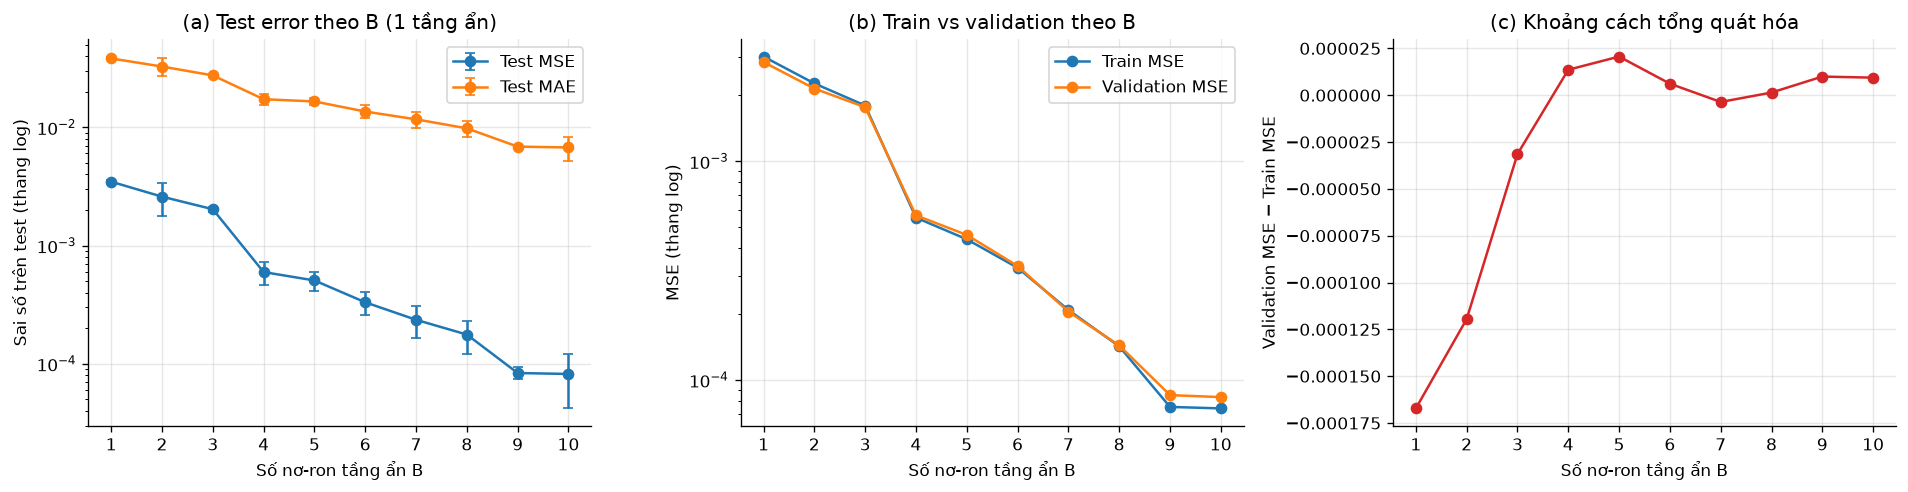

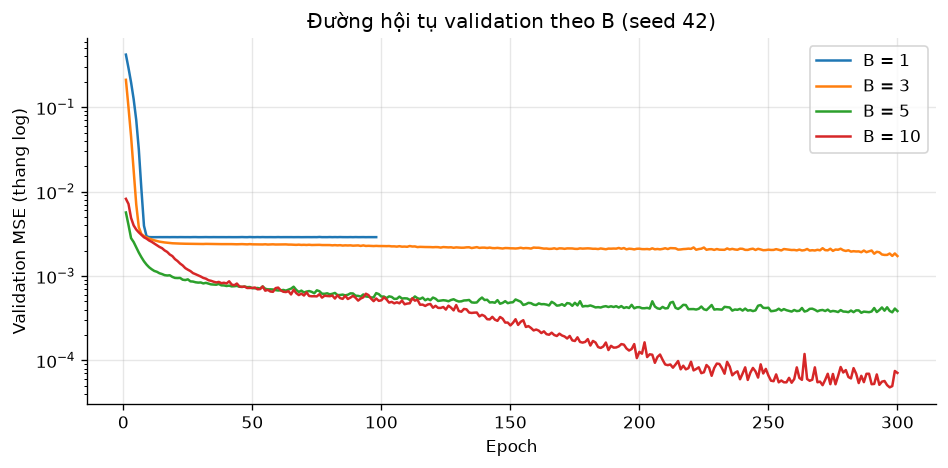

In [14]:
gB = df_B.groupby("B")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
for metric, label in [("test_MSE", "Test MSE"), ("test_MAE", "Test MAE")]:
    m = gB[metric].mean()
    s = gB[metric].std().fillna(0.0)
    ax.errorbar(m.index, m.values, yerr=s.values, marker="o", capsize=3, label=label)
ax.set_yscale("log")
ax.set_xlabel("Số nơ-ron tầng ẩn B")
ax.set_ylabel("Sai số trên test (thang log)")
ax.set_title("(a) Test error theo B (1 tầng ẩn)")
ax.set_xticks(B_VALUES)
ax.legend()

ax = axes[1]
for metric, label in [("train_MSE", "Train MSE"), ("val_MSE", "Validation MSE")]:
    m = gB[metric].mean()
    ax.plot(m.index, m.values, marker="o", label=label)
ax.set_yscale("log")
ax.set_xlabel("Số nơ-ron tầng ẩn B")
ax.set_ylabel("MSE (thang log)")
ax.set_title("(b) Train vs validation theo B")
ax.set_xticks(B_VALUES)
ax.legend()

ax = axes[2]
gap = (gB["val_MSE"].mean() - gB["train_MSE"].mean())
ax.plot(gap.index, gap.values, marker="o", color="#d62728")
ax.set_xlabel("Số nơ-ron tầng ẩn B")
ax.set_ylabel("Validation MSE − Train MSE")
ax.set_title("(c) Khoảng cách tổng quát hóa")
ax.set_xticks(B_VALUES)

fig.tight_layout()
fig.savefig(FIG_DIR / "08_expB_width.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for b in [1, 3, 5, 10]:
    h = pd.read_csv(LOG_DIR / "history_B.csv")
    h = h[(h["B"] == b) & (h["seed"] == 42)]
    ax.plot(h["epoch"], h["val_loss"], label=f"B = {b}")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation MSE (thang log)")
ax.set_title("Đường hội tụ validation theo B (seed 42)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "09_expB_convergence.png", bbox_inches="tight")
plt.show()


### 6.1. Phân tích thực nghiệm B

| $B$ | Test MSE | Test MAE | Train MSE | Validation MSE |
|---|---|---|---|---|
| 1 | $3.46\times10^{-3}$ | $3.82\times10^{-2}$ | $3.01\times10^{-3}$ | $2.84\times10^{-3}$ |
| 2 | $2.59\times10^{-3}$ | $3.26\times10^{-2}$ | $2.27\times10^{-3}$ | $2.15\times10^{-3}$ |
| 3 | $2.03\times10^{-3}$ | $2.75\times10^{-2}$ | $1.80\times10^{-3}$ | $1.77\times10^{-3}$ |
| 4 | $5.96\times10^{-4}$ | $1.73\times10^{-2}$ | $5.52\times10^{-4}$ | $5.66\times10^{-4}$ |
| 5 | $5.06\times10^{-4}$ | $1.65\times10^{-2}$ | $4.40\times10^{-4}$ | $4.60\times10^{-4}$ |
| 6 | $3.31\times10^{-4}$ | $1.36\times10^{-2}$ | $3.26\times10^{-4}$ | $3.32\times10^{-4}$ |
| 7 | $2.35\times10^{-4}$ | $1.17\times10^{-2}$ | $2.09\times10^{-4}$ | $2.05\times10^{-4}$ |
| 8 | $1.77\times10^{-4}$ | $9.79\times10^{-3}$ | $1.43\times10^{-4}$ | $1.44\times10^{-4}$ |
| 9 | $8.35\times10^{-5}$ | $6.86\times10^{-3}$ | $7.53\times10^{-5}$ | $8.53\times10^{-5}$ |
| 10 | $8.20\times10^{-5}$ | $6.75\times10^{-3}$ | $7.42\times10^{-5}$ | $8.35\times10^{-5}$ |

- **Thiếu khớp rõ rệt khi $B$ nhỏ.** Với $B=1$, test MSE $3.46\times10^{-3}$ xấp xỉ phương sai của $y$ — mạng gần như chỉ dự đoán giá trị trung bình. $B=2$ và $B=3$ vẫn rất kém (test MSE $>2\times10^{-3}$, MAE $>2.7\times10^{-2}$) vì một tầng ẩn quá hẹp không biểu diễn được đỉnh nhọn và tương quan âm của hàm mật độ.
- Test MSE **giảm đơn điệu** khi tăng $B$, từ $3.46\times10^{-3}$ xuống $8.20\times10^{-5}$ (khoảng **42 lần**). Bước nhảy lớn nhất nằm giữa $B=3$ và $B=4$ (giảm khoảng 3.4 lần), cho thấy ngưỡng năng lực tối thiểu nằm quanh 4 nơ-ron.
- **Chưa thấy quá khớp** trong dải $B\le10$: train MSE và validation MSE gần như trùng nhau (chênh lệch tuyệt đối $\le1.2\times10^{-5}$). Với $A=1000$, số tham số của mạng vẫn còn nhỏ nên mô hình chưa có đủ năng lực để ghi nhớ dữ liệu.
- Ở $B\ge4$, epoch tốt nhất thường rơi vào **290–299**, tức mạng vẫn đang cải thiện khi chạm giới hạn 300 epoch. Nếu tăng số epoch hoặc mở rộng $B$, sai số còn có thể giảm; kết quả $B=10$ vì vậy là **cận trên của underfitting**, chưa phải điểm bão hòa thực sự.
- So sánh với baseline: mạng 1 tầng ẩn 10 nơ-ron đạt $8.35\times10^{-5}$, vẫn kém khoảng 25 lần so với mạng 2×64 ($3.26\times10^{-6}$). Điều này cho thấy với cùng ngân sách tham số nhỏ, **tăng độ sâu hiệu quả hơn tăng độ rộng đơn thuần** trên hàm mục tiêu này.


## 7. Thực nghiệm C — ảnh hưởng của độ sâu

Khảo sát số tầng ẩn $C \in \{1, 2, 3, 4\}$, cố định $B = 64$ nơ-ron/tầng, $A = 1000$, cùng các siêu tham số huấn luyện. Mỗi cấu hình 3 seed.

Kết quả bắt buộc: test error, đường loss hội tụ và thời gian huấn luyện. Mục tiêu là đánh đổi giữa năng lực biểu diễn, tốc độ hội tụ và chi phí tính toán.


In [15]:
C_VALUES = [1, 2, 3, 4]
df_C = run_group(
    "C",
    [{"A": A_BASE, "hidden_sizes": (B_BASE,) * c} for c in C_VALUES],
)
print(f"Đã chạy {len(df_C)} lượt cho thực nghiệm C.")
display(mean_std_table(df_C, "C", metrics=("val_loss_best", "test_MSE", "test_MAE", "test_RMSE", "train_time_s")))


Đã chạy 12 lượt cho thực nghiệm C.


val_loss_best                test_MSE               test_MAE              test_RMSE             train_time_s         
           mean         std        mean         std       mean         std       mean         std         mean      std
C                                                                                                                      
1   7.53977e-06 2.87389e-06 7.15438e-06 2.82936e-06 0.00207964 0.000405911 0.00263367 0.000572022      6.35017 0.708182
2   4.28827e-06 1.21338e-06 4.22938e-06 9.21517e-07 0.00164599 0.000255159 0.00204812 0.000227745      4.23113 0.282668
3   2.37579e-06  2.7856e-07 2.79817e-06 3.88568e-07 0.00126323 7.38849e-05 0.00166996 0.000118775      4.37262 0.374049
4    1.8831e-06 1.45849e-07 2.51572e-06 2.95042e-07  0.0012093 5.24936e-05 0.00158428 9.31302e-05      4.19582 0.570744

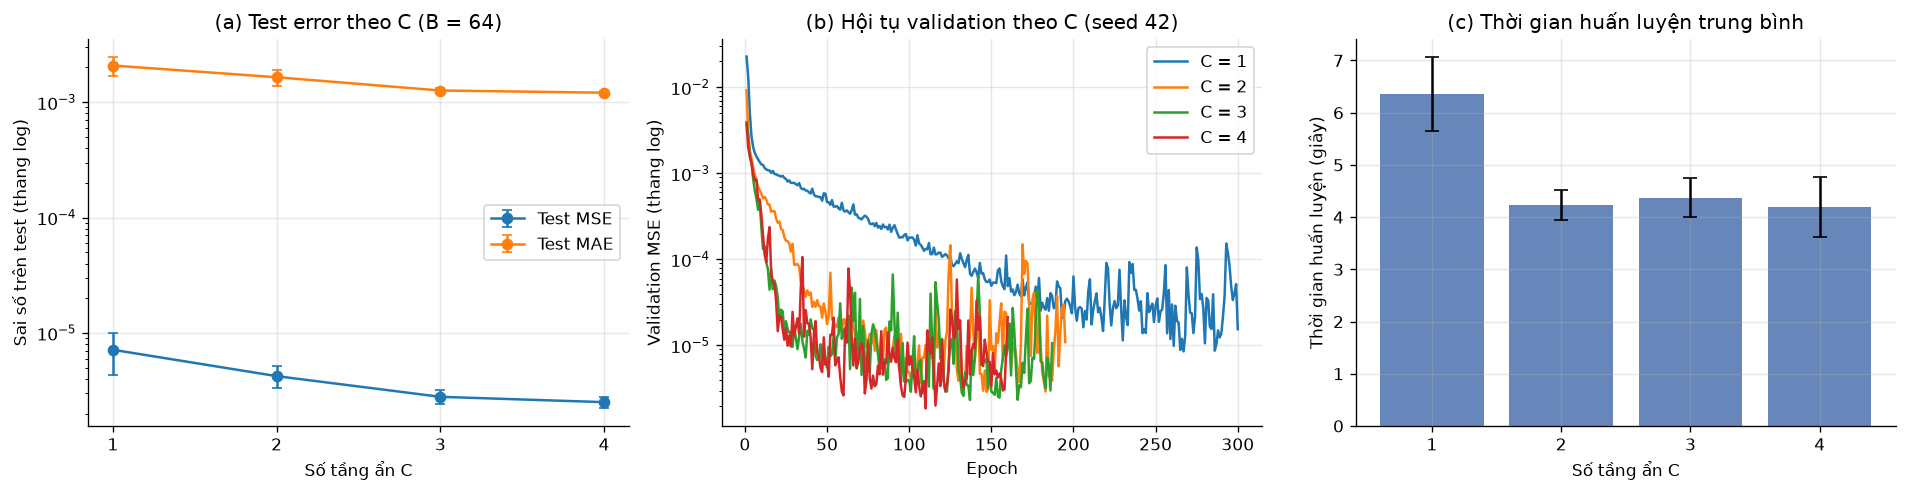

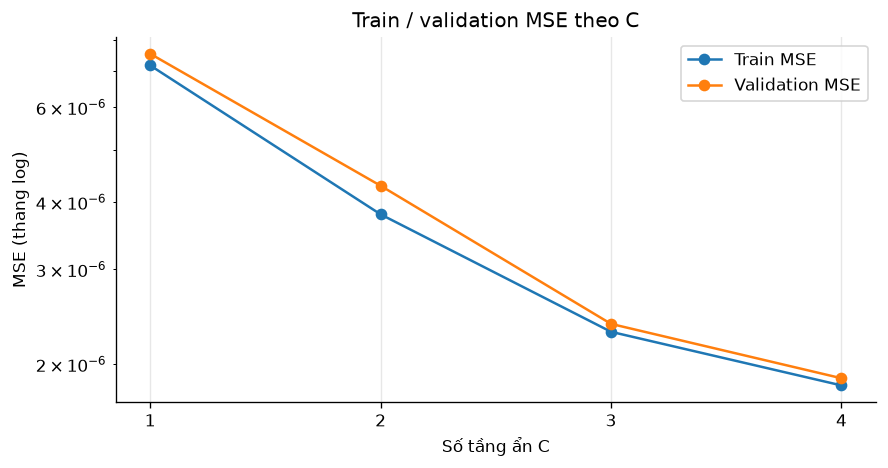

In [16]:
gC = df_C.groupby("C")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
for metric, label in [("test_MSE", "Test MSE"), ("test_MAE", "Test MAE")]:
    m = gC[metric].mean()
    s = gC[metric].std().fillna(0.0)
    ax.errorbar(m.index, m.values, yerr=s.values, marker="o", capsize=3, label=label)
ax.set_yscale("log")
ax.set_xlabel("Số tầng ẩn C")
ax.set_ylabel("Sai số trên test (thang log)")
ax.set_title("(a) Test error theo C (B = 64)")
ax.set_xticks(C_VALUES)
ax.legend()

ax = axes[1]
hC = pd.read_csv(LOG_DIR / "history_C.csv")
for c in C_VALUES:
    h = hC[(hC["C"] == c) & (hC["seed"] == 42)]
    ax.plot(h["epoch"], h["val_loss"], label=f"C = {c}")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation MSE (thang log)")
ax.set_title("(b) Hội tụ validation theo C (seed 42)")
ax.legend()

ax = axes[2]
m = gC["train_time_s"].mean()
s = gC["train_time_s"].std().fillna(0.0)
ax.bar(m.index, m.values, yerr=s.values, capsize=4, color="#4c72b0", alpha=0.85)
ax.set_xlabel("Số tầng ẩn C")
ax.set_ylabel("Thời gian huấn luyện (giây)")
ax.set_title("(c) Thời gian huấn luyện trung bình")
ax.set_xticks(C_VALUES)

fig.tight_layout()
fig.savefig(FIG_DIR / "10_expC_depth.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4))
for metric, label in [("train_MSE", "Train MSE"), ("val_MSE", "Validation MSE")]:
    m = gC[metric].mean()
    ax.plot(m.index, m.values, marker="o", label=label)
ax.set_yscale("log")
ax.set_xlabel("Số tầng ẩn C")
ax.set_ylabel("MSE (thang log)")
ax.set_title("Train / validation MSE theo C")
ax.set_xticks(C_VALUES)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "11_expC_split_gap.png", bbox_inches="tight")
plt.show()


### 7.1. Phân tích thực nghiệm C

| $C$ | Test MSE | Test MAE | Thời gian (s) | Epoch đã chạy | Thời gian/epoch (s) |
|---|---|---|---|---|---|
| 1 | $7.15\times10^{-6}$ | $2.08\times10^{-3}$ | $6.35$ | $294.0$ | $0.0216$ |
| 2 | $4.23\times10^{-6}$ | $1.65\times10^{-3}$ | $4.23$ | $196.7$ | $0.0215$ |
| 3 | $2.80\times10^{-6}$ | $1.26\times10^{-3}$ | $4.37$ | $199.7$ | $0.0219$ |
| 4 | $2.52\times10^{-6}$ | $1.21\times10^{-3}$ | $4.20$ | $183.0$ | $0.0229$ |

- Test MSE giảm từ $7.15\times10^{-6}$ ($C=1$) xuống $2.52\times10^{-6}$ ($C=4$), tức khoảng **2.8 lần**, nhưng **hiệu suất biên giảm nhanh**: bước $C=1\to2$ cải thiện 1.7 lần, trong khi $C=3\to4$ chỉ còn 1.1 lần.
- Đường hội tụ validation (Hình 10b) cho thấy $C=1$ giảm chậm và bị nhiễu ở mức $10^{-5}$; $C=2$–$4$ hội tụ nhanh hơn, đạt vùng $10^{-6}$ sau khoảng 100–150 epoch. Mạng sâu hơn có thêm năng lực biểu diễn nên tối ưu hóa hiệu quả hơn ở giai đoạn đầu.
- **Thời gian/epoch gần như không đổi** ($0.0215$–$0.0229$ s) vì mỗi lô chỉ 64 mẫu và chi phí điều khiển của PyTorch chiếm phần lớn; chỉ khi $C=4$ mới nhích lên khoảng 6%. Tổng thời gian huấn luyện **không tăng đơn điệu** vì bị chi phối bởi số epoch thực tế chạy: $C=1$ cần tới 294 epoch (6.35 s) do hội tụ chậm, còn $C\ge2$ dừng sớm hơn (khoảng 183–200 epoch, 4.2–4.4 s). Đây là lý do nên đọc thời gian/epoch thay vì chỉ nhìn tổng thời gian khi so sánh độ sâu.
- Không có dấu hiệu quá khớp: với $C=4$, train MSE $1.83\times10^{-6}$ và validation MSE $1.88\times10^{-6}$ gần như bằng nhau. Tăng độ sâu trong dải khảo sát chủ yếu cải thiện nhẹ độ chính xác chứ không làm mô hình ghi nhớ dữ liệu.
- Kết luận: $C=2$ là lựa chọn cân bằng giữa sai số và chi phí; $C=3$–$4$ chỉ đáng dùng nếu cần tối ưu thêm sai số rất nhỏ, còn $C=1$ vẫn khả thi nhưng cần nhiều epoch hơn.


## 8. Chọn mô hình bằng validation và đánh giá test cuối

### 8.1. Tổng hợp và lựa chọn

Mô hình được chọn **chỉ dựa trên validation loss** (trung bình qua 3 seed) trong tất cả cấu hình của baseline và ba nhóm A/B/C. Tập test không tham gia vào bước này.

Sau khi chọn cấu hình, huấn luyện lại trên **toàn bộ 2000 mẫu train** (nhiều dữ liệu nhất) với 3 seed, chọn seed có validation loss thấp nhất, lưu checkpoint và **chỉ đánh giá test một lần**.


In [17]:
rows = []

# Baseline
rows.append(
    {
        "group": "baseline",
        "A": A_BASE,
        "B": B_BASE,
        "C": C_BASE,
        "val_loss_mean": base_metrics["validation"]["MSE"],
        "test_MSE_mean": base_metrics["test"]["MSE"],
        "test_MAE_mean": base_metrics["test"]["MAE"],
        "test_RMSE_mean": base_metrics["test"]["RMSE"],
        "train_time_mean": time_base,
    }
)

for group_name, df, key in [("A", df_A, "A"), ("B", df_B, "B"), ("C", df_C, "C")]:
    agg = df.groupby(key).agg(
        A=("A", "mean"),
        B=("B", "mean"),
        C=("C", "mean"),
        val_loss_mean=("val_loss_best", "mean"),
        test_MSE_mean=("test_MSE", "mean"),
        test_MAE_mean=("test_MAE", "mean"),
        test_RMSE_mean=("test_RMSE", "mean"),
        train_time_mean=("train_time_s", "mean"),
    )
    agg["group"] = f"{group_name}:{key}"
    rows.extend(agg.reset_index(drop=True).to_dict("records"))

all_summary = pd.DataFrame(rows)
all_summary = all_summary[
    ["group", "A", "B", "C", "val_loss_mean", "test_MSE_mean", "test_MAE_mean", "test_RMSE_mean", "train_time_mean"]
].sort_values("val_loss_mean")
all_summary.to_csv(LOG_DIR / "summary_all.csv", index=False)
display(all_summary.head(12).reset_index(drop=True))

best_cfg = all_summary.iloc[0]
print("\nCấu hình được chọn theo validation loss:")
print(best_cfg.to_string())


,group,A,B,C,val_loss_mean,test_MSE_mean,test_MAE_mean,test_RMSE_mean,train_time_mean
0,A:A,1600,64,2,1.14283e-06,1.40866e-06,0.00091283,0.00117094,6.46631
1,A:A,2000,64,2,1.18393e-06,1.22293e-06,0.000876953,0.00110499,7.54833
2,A:A,1200,64,2,1.27336e-06,1.29178e-06,0.000918251,0.00113424,5.69715
3,A:A,1400,64,2,1.34736e-06,1.39944e-06,0.00090976,0.00115532,5.88887
4,A:A,1800,64,2,1.79759e-06,2.05889e-06,0.00109328,0.00142966,6.49611
5,C:C,1000,64,4,1.8831e-06,2.51572e-06,0.0012093,0.00158428,4.19582
6,C:C,1000,64,3,2.37579e-06,2.79817e-06,0.00126323,0.00166996,4.37262
7,A:A,800,64,2,2.86776e-06,2.91176e-06,0.0012752,0.00163634,3.84876
8,baseline,1000,64,2,2.98034e-06,3.25716e-06,0.00136809,0.00180476,3.58121
9,C:C,1000,64,2,4.28827e-06,4.22938e-06,0.00164599,0.00204812,4.23113



Cấu hình được chọn theo validation loss:
group                     A:A
A                        1600
B                          64
C                           2
val_loss_mean     1.14283e-06
test_MSE_mean     1.40866e-06
test_MAE_mean      0.00091283
test_RMSE_mean     0.00117094
train_time_mean       6.46631


In [18]:
best_hidden = (int(best_cfg["B"]),) * int(best_cfg["C"])
print("Kiến trúc cuối:", best_hidden)

final_runs = []
for seed in EXP_SEEDS:
    model, hist, best, train_time = train_model(
        X_train_pool,
        y_train_pool,
        X_val,
        y_val,
        hidden_sizes=best_hidden,
        seed=seed,
        save_path=RUN_DIR / f"final_full_A2000_s{seed}.pt",
    )
    m_val = regression_metrics(y_val, predict(model, X_val))
    m_test = regression_metrics(y_test, predict(model, X_test))
    final_runs.append(
        {
            "seed": seed,
            "val_MSE": m_val["MSE"],
            "test_MSE": m_test["MSE"],
            "test_MAE": m_test["MAE"],
            "test_RMSE": m_test["RMSE"],
            "best_epoch": best["epoch"],
            "train_time_s": train_time,
            "_model": model,
        }
    )

final_df = pd.DataFrame([{k: v for k, v in r.items() if k != "_model"} for r in final_runs])
display(final_df)

best_final_idx = int(np.argmin([r["val_MSE"] for r in final_runs]))
best_final = final_runs[best_final_idx]
final_model = best_final["_model"]

final_payload = {
    "state_dict": copy.deepcopy(final_model.state_dict()),
    "hidden_sizes": best_hidden,
    "activation": ACTIVATION,
    "seed": int(best_final["seed"]),
    "selected_by": "validation loss",
    "val_MSE": float(best_final["val_MSE"]),
    "test_MSE": float(best_final["test_MSE"]),
    "test_MAE": float(best_final["test_MAE"]),
    "test_RMSE": float(best_final["test_RMSE"]),
    "trained_on": "2000 training samples",
}
torch.save(final_payload, MODEL_DIR / "best_model.pt")
final_df.to_csv(LOG_DIR / "final_test_results.csv", index=False)

final_test_metrics = regression_metrics(y_test, predict(final_model, X_test))
print("Đánh giá test cuối cùng (chỉ một lần):", final_test_metrics)
print("Checkpoint:", MODEL_DIR / "best_model.pt")


Kiến trúc cuối: (64, 64)


,seed,val_MSE,test_MSE,test_MAE,test_RMSE,best_epoch,train_time_s
0,42,1.15874e-06,1.30393e-06,0.000907961,0.0011419,153,7.14473
1,43,1.37639e-06,1.27614e-06,0.000925456,0.00112966,145,6.65946
2,44,1.01666e-06,1.08872e-06,0.000797442,0.00104342,209,8.81929


Đánh giá test cuối cùng (chỉ một lần): {'MSE': 1.0887218877542182e-06, 'MAE': 0.0007974415784701705, 'RMSE': 0.0010434183665980863}
Checkpoint: D:\workspace\DeepLearning_DDU1231\BTL01\outputs\models\best_model.pt


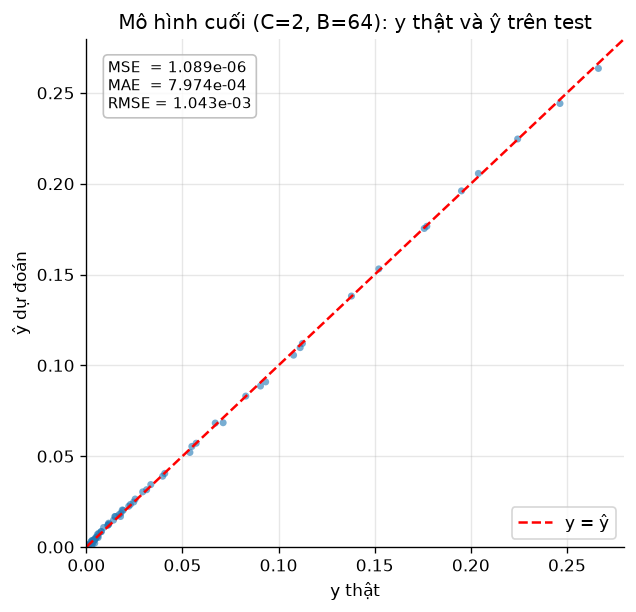

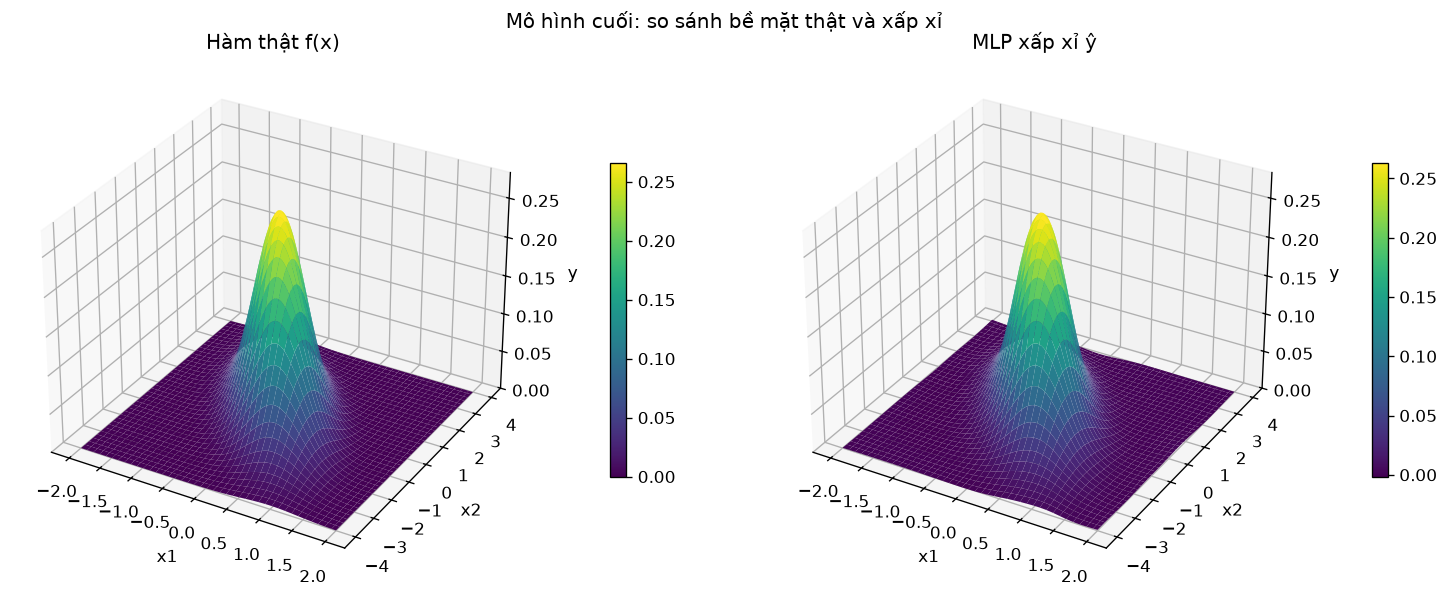

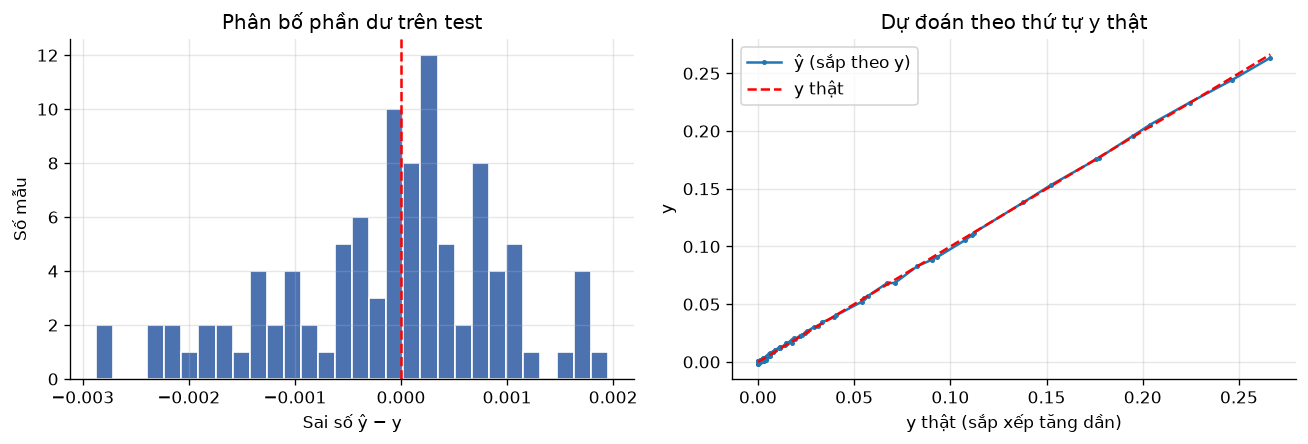

In [19]:
plot_y_vs_yhat(
    y_test,
    predict(final_model, X_test),
    final_test_metrics,
    FIG_DIR / "12_final_y_vs_yhat.png",
    f"Mô hình cuối (C={len(best_hidden)}, B={best_hidden[0]}): y thật và ŷ trên test",
)
plot_surface_compare(
    final_model,
    FIG_DIR / "13_final_surface.png",
    "Mô hình cuối: so sánh bề mặt thật và xấp xỉ",
)

residual = predict(final_model, X_test) - y_test
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(residual, bins=30, color="#4c72b0", edgecolor="white")
axes[0].axvline(0, color="r", ls="--")
axes[0].set_xlabel("Sai số ŷ − y")
axes[0].set_ylabel("Số mẫu")
axes[0].set_title("Phân bố phần dư trên test")

order = np.argsort(y_test)
axes[1].plot(y_test[order], predict(final_model, X_test)[order], marker=".", ms=4, label="ŷ (sắp theo y)")
axes[1].plot(y_test[order], y_test[order], "r--", label="y thật")
axes[1].set_xlabel("y thật (sắp xếp tăng dần)")
axes[1].set_ylabel("y")
axes[1].set_title("Dự đoán theo thứ tự y thật")
axes[1].legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "14_final_residuals.png", bbox_inches="tight")
plt.show()


### 8.2. Nhận xét đánh giá cuối

- Cấu hình được chọn **theo validation loss**: $A=1600$, hai tầng ẩn × 64, `tanh` (validation MSE trung bình $1.14\times10^{-6}$). Sau đó mô hình được huấn luyện lại trên **toàn bộ 2000 mẫu**; trong 3 seed, seed 44 có validation MSE thấp nhất ($1.02\times10^{-6}$) nên được lưu làm `best_model.pt`.
- **Kết quả test cuối:** MSE $=1.09\times10^{-6}$, MAE $=7.97\times10^{-4}$, RMSE $=1.04\times10^{-3}$.
- So với baseline (test MSE $3.26\times10^{-6}$, MAE $1.37\times10^{-3}$), mô hình cuối giảm MSE khoảng **3.0 lần** và MAE khoảng **1.7 lần**. Mức cải thiện này phù hợp với xu hướng của thực nghiệm A khi tăng $A$ từ 1000 lên 2000.
- Phần dư (Hình 14) tập trung quanh 0, không có xu hướng hệ thống; scatter $y$–$\hat{y}$ và bề mặt xấp xỉ cho thấy mô hình nắm được cả vùng đỉnh lẫn vùng đuôi. Một vài mẫu ở đuôi có sai số lớn hơn nhưng đóng góp vào MSE không đáng kể vì $y$ ở đó rất nhỏ.
- Việc chọn mô hình chỉ dựa trên validation; các bảng test ở mục 5–7 phục vụ báo cáo thực nghiệm, không dùng để tinh chỉnh. Vì vậy kết quả test cuối vẫn là ước lượng khách quan.


## 9. Tổng kết

Bảng tổng hợp kết quả test (trung bình 3 seed, riêng baseline và mô hình cuối là một lượt đánh giá):

| Cấu hình | Test MSE | Test MAE | Test RMSE |
|---|---|---|---|
| Baseline: $A=1000$, 2×64 | $3.26\times10^{-6}$ | $1.37\times10^{-3}$ | $1.80\times10^{-3}$ |
| A tốt nhất: $A=1600$, 2×64 | $1.41\times10^{-6}$ | $9.13\times10^{-4}$ | $1.17\times10^{-3}$ |
| B tốt nhất: $B=10$, 1 tầng ẩn | $8.20\times10^{-5}$ | $6.75\times10^{-3}$ | $8.86\times10^{-3}$ |
| C tốt nhất: $C=4$, $B=64$ | $2.52\times10^{-6}$ | $1.21\times10^{-3}$ | $1.58\times10^{-3}$ |
| **Mô hình cuối** (2×64, 2000 mẫu) | $\mathbf{1.09\times10^{-6}}$ | $\mathbf{7.97\times10^{-4}}$ | $\mathbf{1.04\times10^{-3}}$ |

### Kết quả chính

1. **Dữ liệu:** hàm Gaussian 2D cài đúng công thức; kiểm tra tích phân xấp xỉ $\approx1$; ba tập train/validation/test độc lập với seed công bố; trực quan hóa đầy đủ scatter 3D, mặt thật, heatmap và phân bố biên.
2. **Mô hình:** MLP tùy biến bằng `nn.Module`/`nn.Linear`; vòng lặp huấn luyện thủ công đầy đủ forward–backward–step; checkpoint và early stopping chỉ dựa trên validation loss.
3. **Thực nghiệm A:** tăng $A$ giảm sai số khoảng 19 lần từ $A=200$ đến $2000$; hiệu suất biên giảm rõ sau $A\approx1000$–$1200$.
4. **Thực nghiệm B:** $B\le3$ thiếu khớp nghiêm trọng; sai số giảm đơn điệu tới $B=10$ nhưng **chưa bão hòa**; chưa thấy quá khớp trong dải khảo sát.
5. **Thực nghiệm C:** $C=1$–$2$ đã đủ tốt; tăng lên $C=3$–$4$ chỉ cải thiện nhẹ, thời gian/epoch gần như không đổi nhưng tổng thời gian phụ thuộc số epoch do early stopping.
6. **Mô hình cuối** (2×64, huấn luyện trên 2000 mẫu) đạt test MSE $1.09\times10^{-6}$ và MAE $7.97\times10^{-4}$, tốt hơn baseline khoảng 3 lần về MSE.

### Hạn chế và hướng cải tiến

- Chỉ chạy CPU với mạng nhỏ; chưa khảo sát learning-rate schedule, weight decay, BatchNorm, residual connection hay các activation khác (ReLU, GELU, SiLU).
- Dữ liệu không nhiễu và hàm mục tiêu trơn nên kết quả khá lạc quan; với dữ liệu thực cần thêm nhiễu, kiểm tra chéo $k$-fold và phân tích độ bất định.
- Có thể mở rộng $B$ lên 32/64/128 và tăng số epoch để quan sát rõ hơn ranh giới underfitting–overfitting; đồng thời khảo sát ảnh hưởng của learning rate và batch size.
- Vùng đuôi có $y$ rất nhỏ vẫn chiếm đa số mẫu; nên bổ sung trọng số mất mát hoặc lấy mẫu ưu tiên vùng mật độ cao nếu cần tối ưu MAE tương đối.

### Tái lập

Chạy tuần tự toàn bộ notebook từ thư mục `BTL01/` (kernel Python có PyTorch). Toàn bộ kết quả được ghi vào:

- `outputs/data/` — CSV dữ liệu ba tập.
- `outputs/logs/` — cấu hình, kết quả từng lượt chạy (`results_A/B/C.csv`, `results_baseline.csv`), lịch sử loss và bảng tổng hợp `summary_all.csv`.
- `outputs/figures/` — 14 hình minh họa.
- `outputs/models/` — checkpoint từng lượt chạy (thư mục `runs/`), `best_model.pt` của mô hình cuối.
